# Regional internal migration in Kazakhstan

**Aruzhan Rysbayeva and Alua Sagyndyk · SE-2403 · Assignment 3**

Open in Colab and run all cells from the top. The first code cell clones the complete repository when its modules and data are absent. Uploading only the notebook without this setup would cause `ModuleNotFoundError: build_dataset`.

Seven frozen official BNS workbooks were downloaded on 24 October 2026. This is a retrospective temporal benchmark, not an operational live forecast. Package versions are recorded in `results/environment.json`; the exact original environment is specified in `requirements.txt`.


In [1]:
# Prepare the complete project when opening this notebook directly in Colab.
from pathlib import Path
import os, subprocess, sys

repository_url = "https://github.com/aluasagyndyk2/kazakhstan-internal-migration-ml.git"
project = Path.cwd()
if not (project / "source_manifest.json").is_file():
    candidate = project / "kazakhstan-internal-migration-ml"
    if not (candidate / "source_manifest.json").is_file():
        if candidate.exists():
            raise RuntimeError("The destination exists but is not this project. Choose an empty working directory.")
        subprocess.run(["git", "clone", repository_url, str(candidate)], check=True)
    project = candidate.resolve()
    os.chdir(project)
sys.path.insert(0, str(project))
assert (project / "build_dataset.py").is_file()
assert (project / "run_analysis.py").is_file()
print("Project modules and original BNS data are ready.")


Project modules and original BNS data are ready.


In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from build_dataset import build_dataset
from run_analysis import main
project = Path.cwd()
assert (project / "source_manifest.json").exists()
print("Frozen data sources")
display(pd.read_json("source_manifest.json")[["id", "title_ru", "url", "updated", "accessed"]])

Frozen data sources


,id,title_ru,url,updated,accessed
0,population,Среднегодовая численность населения (по годам),https://stat.gov.kz/api/iblock/element/6576/fi...,27.03.2026,2026-10-24
1,migration_in,Внутренняя миграция по всем потокам - прибытие...,https://stat.gov.kz/api/iblock/element/449808/...,25.09.2026,2026-10-24
2,migration_out,Внутренняя миграция по всем потокам - выбытие ...,https://stat.gov.kz/api/iblock/element/449809/...,25.09.2026,2026-10-24
3,migration_net,Сальдо внутренней миграции по всем потокам (по...,https://stat.gov.kz/api/iblock/element/449807/...,25.09.2026,2026-10-24
4,unemployment,Уровень безработицы,https://stat.gov.kz/api/iblock/element/102790/...,19.06.2026,2026-10-24
5,income,Среднедушевые номинальные денежные доходы насе...,https://stat.gov.kz/api/iblock/element/19298/f...,02.10.2026,2026-10-24
6,wages,Среднемесячная заработная плата по регионам Ре...,https://stat.gov.kz/api/iblock/element/5676/fi...,10.09.2026,2026-10-24


## Extract and validate the real data
Workbooks are read without changing their contents. Every extracted cell is logged. Conservative territorial exclusions are applied before constructing the five lagged predictors.

In [3]:
dataset = build_dataset()
display(dataset.groupby("year").target.agg(["size", "sum"]))
display(dataset[["region", "year", "feature_year", "income_ratio_lag1", "wage_ratio_lag1", "unemployment_lag1", "urban_share_lag1", "log_population_lag1", "target"]].head(10))

{
  "raw_rows": 240,
  "candidate_rows": 220,
  "model_rows": 164,
  "excluded_rows": 56,
  "development_rows": 124,
  "test_rows": 40,
  "positive": 40,
  "negative": 124,
  "features": [
    "income_ratio_lag1",
    "wage_ratio_lag1",
    "unemployment_lag1",
    "urban_share_lag1",
    "log_population_lag1"
  ],
  "feature_missing": 0,
  "territory_strategy": "Conservative unbalanced panel; all 20 current units from outcome year 2023; split-affected regions omitted earlier, not imputed"
}
      rows  positive  negative
year                          
2015    12         6         6
2016    12         2        10
2017    12         3         9
2018    12         2        10
2019    14         4        10
2020    14         4        10
2021    14         4        10
2022    14         3        11
2023    20         3        17
2024    20         4        16
2025    20         5        15


,size,sum
year,,
2015,12,6
2016,12,2
2017,12,3
2018,12,2
2019,14,4
2020,14,4
2021,14,4
2022,14,3
2023,20,3


,region,year,feature_year,income_ratio_lag1,wage_ratio_lag1,unemployment_lag1,urban_share_lag1,log_population_lag1,target
0,Akmola,2015,2014,0.847434,0.705764,4.9,0.481643,13.507352,1
1,Aktobe,2015,2014,0.964206,0.878071,4.9,0.681395,13.611148,0
2,Atyrau,2015,2014,2.002610,1.831622,5.0,0.540110,13.261466,0
3,West Kazakhstan,2015,2014,0.996090,0.894249,5.0,0.494815,13.348512,1
4,Zhambyl,2015,2014,0.638561,0.676525,4.9,0.403150,13.901830,0
5,Kostanay,2015,2014,0.829162,0.748653,5.0,0.547592,13.688388,1
6,Kyzylorda,2015,2014,0.802897,0.863365,5.0,0.429750,13.522057,0
7,Mangystau,2015,2014,1.648342,1.836824,5.0,0.468521,13.300829,1
8,Pavlodar,2015,2014,1.028180,0.845397,4.8,0.699902,13.533152,1
9,North Kazakhstan,2015,2014,0.820255,0.669819,5.0,0.424646,13.259080,0


## Train and evaluate
Fixed model configurations; expanding validation years 2019-2023; the selected model is frozen before the 2024-2025 test is scored. No test-driven tuning is performed.

In [4]:
main()

Actual run completed on 2026-10-24
Raw panel: 240 rows; model dataset: 164 rows
Development: 124; held-out test: 40
Features: income_ratio_lag1, wage_ratio_lag1, unemployment_lag1, urban_share_lag1, log_population_lag1
Validation: expanding windows, outcomes 2019 through 2023
Selected before test: Random Forest

VALIDATION
              model  validation_macro_f1  validation_macro_f1_sd  validation_balanced_accuracy  validation_accuracy
     Majority dummy             0.429892                0.019372                      0.500000             0.755714
Logistic Regression             0.803357                0.083493                      0.844144             0.837143
      Decision Tree             0.801193                0.064655                      0.862406             0.835714
      Random Forest             0.898561                0.108395                      0.931845             0.918571
  Gradient Boosting             0.870615                0.087319                      0.919171 

In [5]:
print("Held-out results")
display(pd.read_csv("results/test_metrics.csv"))
print("Validation feature importance")
display(pd.read_csv("results/feature_importance.csv"))
print("Selected-model errors")
display(pd.read_csv("results/selected_model_errors.csv"))

Held-out results


,model,selected_before_test,n,positive,accuracy,balanced_accuracy,macro_f1,precision_positive,recall_positive,roc_auc,average_precision,tn,fp,fn,tp
0,Majority dummy,False,40,9,0.775,0.500000,0.436620,0.00,0.000000,0.500000,0.225000,31,0,9,0
1,Logistic Regression,False,40,9,0.875,0.801075,0.813259,0.75,0.666667,0.709677,0.742932,29,2,3,6
2,Decision Tree,False,40,9,0.825,0.768817,0.758412,0.60,0.666667,0.731183,0.741667,27,4,3,6
3,Random Forest,True,40,9,0.875,0.801075,0.813259,0.75,0.666667,0.666667,0.734927,29,2,3,6
4,Gradient Boosting,False,40,9,0.875,0.801075,0.813259,0.75,0.666667,0.775986,0.760462,29,2,3,6
5,Previous-year sign,False,40,9,0.950,0.888889,0.921875,1.00,0.777778,0.888889,0.827778,31,0,2,7


Validation feature importance


,feature,mean_drop_macro_f1,sd_permutations
0,urban_share_lag1,0.224348,0.083877
1,income_ratio_lag1,0.061510,0.101670
2,log_population_lag1,0.031889,0.063000
3,unemployment_lag1,0.000000,0.000000
4,wage_ratio_lag1,-0.018058,0.046421


Selected-model errors


,model,kato,region,year,target,prediction,probability,correct
0,Random Forest,190000000,Almaty region,2024,1,0,0.034123,False
1,Random Forest,230000000,Atyrau,2024,0,1,0.518455,False
2,Random Forest,110000000,Akmola,2025,1,0,0.052200,False
3,Random Forest,190000000,Almaty region,2025,1,0,0.037457,False
4,Random Forest,230000000,Atyrau,2025,0,1,0.540423,False


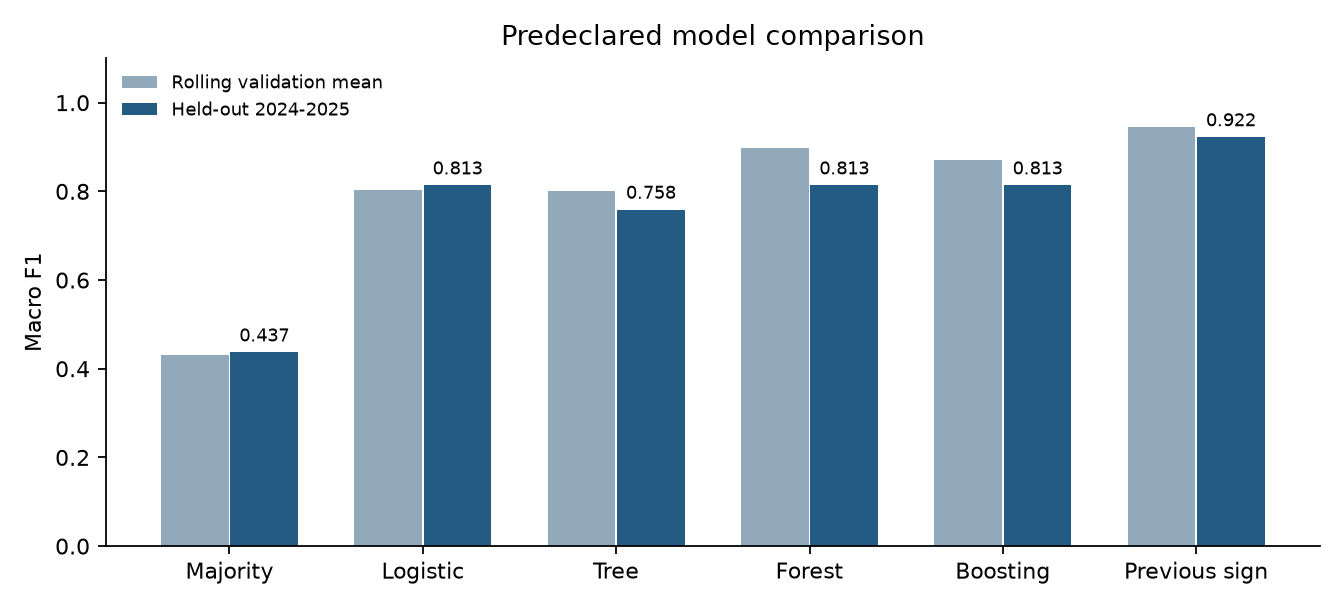

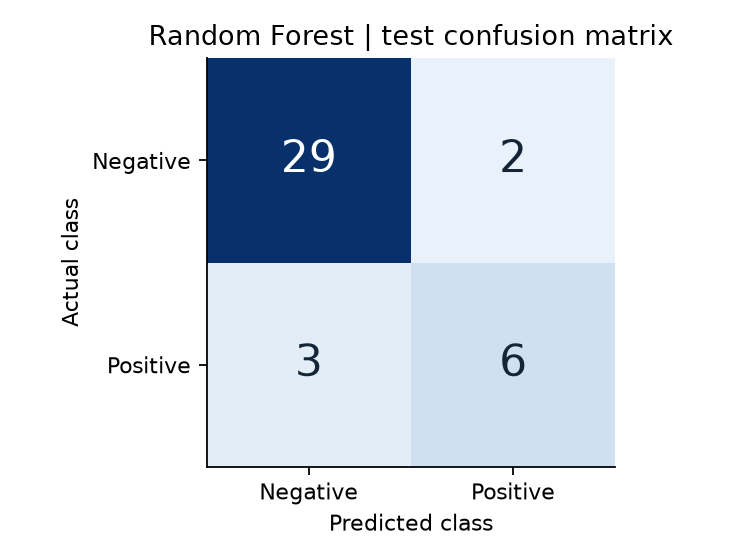

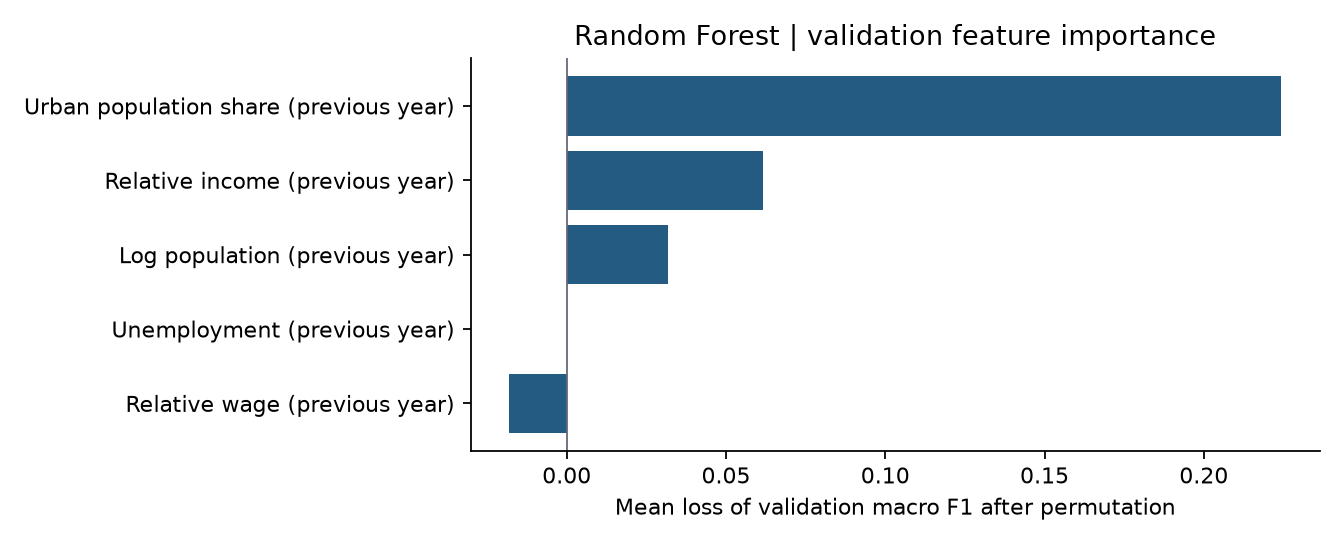

In [6]:
display(Image(filename="results/figures/model_comparison.png"))
display(Image(filename="results/figures/confusion_matrix.png"))
display(Image(filename="results/figures/feature_importance.png"))

## Interpretation
Random Forest was selected on rolling validation. On the held-out test its accuracy equals Logistic Regression rather than improving on it. The previous-year-sign benchmark performs better. The results therefore do not support H1 in this initial implementation. Small samples, repeated regions, revised source data, publication lags, territorial exclusions and regional aggregation limit interpretation. Permutation importance describes model reliance, not causal effects.